In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/nih-chest-xrays/sample/sample_labels.csv
/kaggle/input/datasets/nih-chest-xrays/sample/sample/sample_labels.csv
/kaggle/input/datasets/nih-chest-xrays/sample/sample/images/00000013_005.png
/kaggle/input/datasets/nih-chest-xrays/sample/sample/images/00000013_026.png
/kaggle/input/datasets/nih-chest-xrays/sample/sample/images/00000017_001.png
/kaggle/input/datasets/nih-chest-xrays/sample/sample/images/00000030_001.png
/kaggle/input/datasets/nih-chest-xrays/sample/sample/images/00000032_001.png
/kaggle/input/datasets/nih-chest-xrays/sample/sample/images/00000040_003.png
/kaggle/input/datasets/nih-chest-xrays/sample/sample/images/00000042_002.png
/kaggle/input/datasets/nih-chest-xrays/sample/sample/images/00000057_001.png
/kaggle/input/datasets/nih-chest-xrays/sample/sample/images/00000061_002.png
/kaggle/input/datasets/nih-chest-xrays/sample/sample/images/00000061_019.png
/kaggle/input/datasets/nih-chest-xrays/sample/sample/images/00000061_025.png
/kaggle/input/data

CSV: /kaggle/input/datasets/nih-chest-xrays/sample/sample_labels.csv
Images found: 11212
(5606, 11)


,Image Index,Finding Labels,Follow-up #,Patient ID,Patient Age,Patient Gender,View Position,OriginalImageWidth,OriginalImageHeight,OriginalImagePixelSpacing_x,OriginalImagePixelSpacing_y
0,00000013_005.png,Emphysema|Infiltration|Pleural_Thickening|Pneu...,5,13,060Y,M,AP,3056,2544,0.139,0.139
1,00000013_026.png,Cardiomegaly|Emphysema,26,13,057Y,M,AP,2500,2048,0.168,0.168
2,00000017_001.png,No Finding,1,17,077Y,M,AP,2500,2048,0.168,0.168
3,00000030_001.png,Atelectasis,1,30,079Y,M,PA,2992,2991,0.143,0.143
4,00000032_001.png,Cardiomegaly|Edema|Effusion,1,32,055Y,F,AP,2500,2048,0.168,0.168


Finding Labels
No Finding            3044
Infiltration           967
Effusion               644
Atelectasis            508
Nodule                 313
Mass                   284
Pneumothorax           271
Consolidation          226
Pleural_Thickening     176
Cardiomegaly           141
Emphysema              127
Edema                  118
Fibrosis                84
Pneumonia               62
Hernia                  13
Name: count, dtype: int64


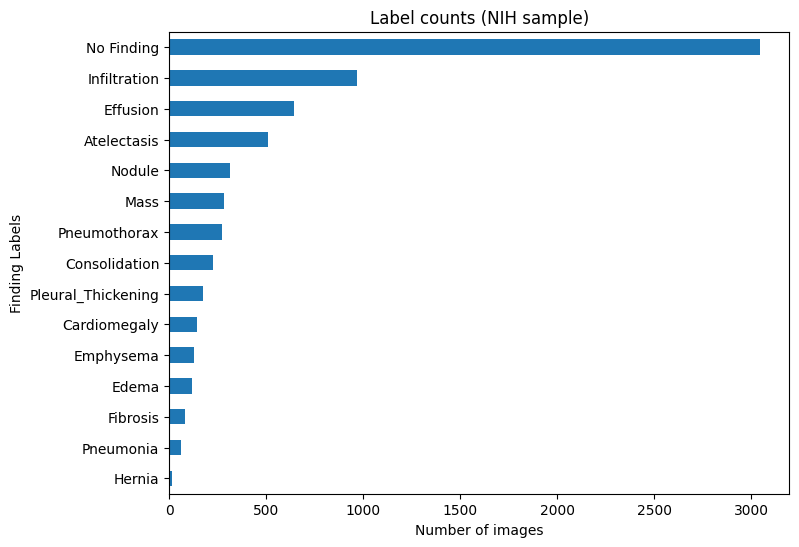

In [1]:
import glob, os
import pandas as pd
import matplotlib.pyplot as plt

# Find the labels CSV and images automatically (folder layout can vary)
csv_path = glob.glob('/kaggle/input/**/sample_labels.csv', recursive=True)[0]
img_paths = glob.glob('/kaggle/input/**/*.png', recursive=True)
print("CSV:", csv_path)
print("Images found:", len(img_paths))

df = pd.read_csv(csv_path)
print(df.shape)
display(df.head())

# Each image can have several diseases, separated by "|"
labels = df['Finding Labels'].str.split('|').explode()
counts = labels.value_counts()
print(counts)

counts.plot(kind='barh', figsize=(8, 6), title='Label counts (NIH sample)')
plt.gca().invert_yaxis()
plt.xlabel('Number of images')
plt.show()

count    5606.000000
mean       46.770068
std        17.407436
min         1.000000
25%        35.000000
50%        49.000000
75%        59.000000
max       411.000000
Name: Age, dtype: float64


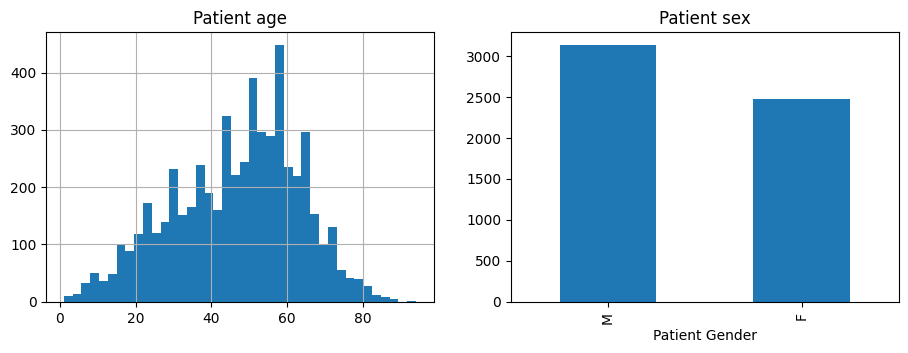

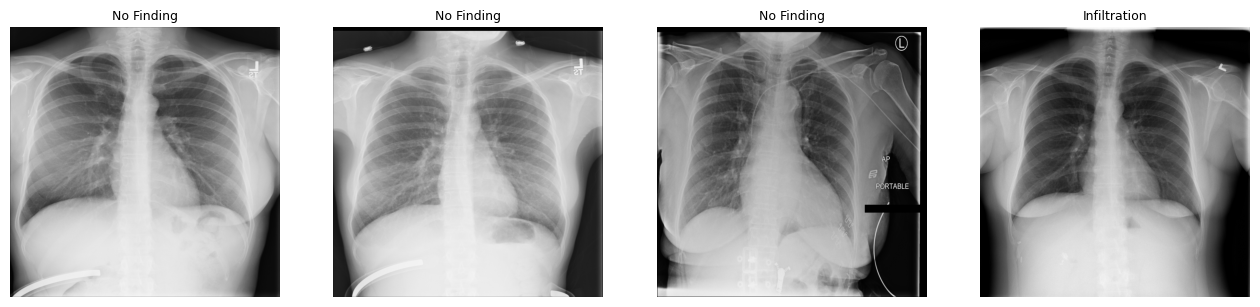

In [4]:
from PIL import Image

# Age is text like "060Y" in this CSV -> turn it into a number
df['Age'] = df['Patient Age'].astype(str).str.extract(r'(\d+)')[0].astype(float)
print(df['Age'].describe())

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
df[df['Age'] < 120]['Age'].hist(bins=40, ax=ax[0])
ax[0].set_title('Patient age')
df['Patient Gender'].value_counts().plot(kind='bar', ax=ax[1], title='Patient sex')
plt.show()

# 4 example X-rays with their labels
path_by_name = {os.path.basename(p): p for p in img_paths}
fig, ax = plt.subplots(1, 4, figsize=(16, 4.5))
for a, (_, row) in zip(ax, df.sample(4, random_state=0).iterrows()):
    a.imshow(Image.open(path_by_name[row['Image Index']]), cmap='gray')
    a.set_title(row['Finding Labels'], fontsize=9)
    a.axis('off')
plt.show()